# 01 - Clip LAS to raster tiles (Site 1)

This notebook mirrors the `clipping_toRaster_onefile.py` and `clipping_toRaster_daskMultiples.py` workflow using the packaged `rasterclip` functions.

- Pre-crops in LAS/native CRS using raster bounds transformed to LAS CRS
- Reprojects output to raster CRS
# --- Overlay: Raster 5/3/1 + LAS ---

In [1]:
# Ensure the local step_1_clipping package is importable in this notebook.
import importlib.util
import sys
from pathlib import Path


def resolve_rasterclip_root() -> Path:
    cwd = Path.cwd().resolve()
    direct_candidates = [cwd, cwd.parent, cwd.parent.parent]
    for base in direct_candidates:
        if (base / "rasterclip" / "__init__.py").exists():
            return base

    nested_candidates = [
        base / "phase_4_3D_lidar_prep" / "step_1_clipping"
        for base in direct_candidates
    ]
    for base in nested_candidates:
        if (base / "rasterclip" / "__init__.py").exists():
            return base

    raise ModuleNotFoundError(
        "Could not locate the local 'rasterclip' package. "
        "Open this notebook from the repository workspace or install it with "
        "'pip install -e phase_4_3D_lidar_prep/step_1_clipping'."
    )


if importlib.util.find_spec("rasterclip") is None:
    rasterclip_root = resolve_rasterclip_root()
    sys.path.insert(0, str(rasterclip_root))
    print(f"Added rasterclip source root: {rasterclip_root}")
else:
    print("rasterclip already available in the active kernel")

Added rasterclip source root: /home/laura/Documents/code/fvc_structure/phase_4_3D_lidar_prep/step_1_clipping


In [9]:
# RGB point clouds
from pathlib import Path

# --- CONFIGURATION: Site 1 (DD0001) ---
SITE_NAME = 'site1_DD0001'

# Input LAS (coreg)
INPUT_RGB_LAS = Path("/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/SASMDD0001_rgb_pc.las")

# Raster tiles directory and pattern
RGB_AOI_RASTER_DIR = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16/')
RGB_RASTER_PATTERN = 'tiles_multispectral*.tif'

# Single tile example
RGB_TILE_ID = '109'
RGB_A_TILE = RGB_AOI_RASTER_DIR / f'tiles_multispectral_{RGB_TILE_ID}.tif'

# Output directory
RGB_OUT_DIR = Path("/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/clipped/raster_v2")
RGB_OUT_DIR.mkdir(parents=True, exist_ok=True)

print('--- RGB Configuration ---')
print(f'Raster dir  : {RGB_AOI_RASTER_DIR}')
print(f'LAS dir     : {INPUT_RGB_LAS}')
print(f'Pattern     : {RGB_RASTER_PATTERN}')
print(f'Single tile : {RGB_TILE_ID}')
print(f'Output dir  : {RGB_OUT_DIR}')
print('-------------------------')

--- RGB Configuration ---
Raster dir  : /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16
LAS dir     : /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/SASMDD0001_rgb_pc.las
Pattern     : tiles_multispectral*.tif
Single tile : 109
Output dir  : /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/clipped/raster_v2
-------------------------


In [18]:
# Coregistered LiDAR point clouds
from pathlib import Path

# --- CONFIGURATION: Site 1 (DD0001) ---
SITE_NAME = 'site1_DD0001'

# Input LAS (coreg)
INPUT_LAS = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las')

# Raster tiles directory and pattern
LIDAR_AOI_RASTER_DIR = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16/')
LIDAR_RASTER_PATTERN = 'tiles_multispectral*.tif'

# Single tile example
LIDAR_TILE_ID = '109'
LIDAR_A_TILE = LIDAR_AOI_RASTER_DIR / f'tiles_multispectral_{LIDAR_TILE_ID}.tif'

# Output directory
LIDAR_OUT_DIR = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/raster_v2/coreg')
LIDAR_OUT_DIR.mkdir(parents=True, exist_ok=True)

print('--- LiDAR Configuration ---')
print(f'Raster dir  : {LIDAR_AOI_RASTER_DIR}')
print(f'LAS dir     : {INPUT_LAS}')
print(f'Pattern     : {LIDAR_RASTER_PATTERN}')
print(f'Single tile : {LIDAR_TILE_ID}')
print(f'Output dir  : {LIDAR_OUT_DIR}')
print('---------------------------')

--- LiDAR Configuration ---
Raster dir  : /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16
LAS dir     : /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
Pattern     : tiles_multispectral*.tif
Single tile : 109
Output dir  : /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/raster_v2/coreg
---------------------------


In [ ]:
# --- Single tile clip (optional; can be slow) ---
import time
from rasterclip import clip_single

out_single = LIDAR_OUT_DIR / f'{LIDAR_A_TILE.stem}.las'
print('Starting single-tile clip...')
t0 = time.time()
pts = clip_single(INPUT_LAS, LIDAR_A_TILE, out_single)
dt = time.time() - t0
print(f'✅ Single tile written: {out_single} ({pts} points) in {dt:.2f}s')
print('Tip: If single-tile is slow, run Dask batch directly for better throughput.')

Starting single-tile clip...
✅ Single tile written: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/raster_v2/coreg/tiles_multispectral_109.las (1595802 points) in 183.67s
Tip: If single-tile is slow, run Dask batch directly for better throughput.


In [ ]:
# --- Batch clip: sequential and Dask with signature ---
from rasterclip import clip_many, clip_many_dask
from pathlib import Path

# Sequential
outs_seq = clip_many(INPUT_LAS, LIDAR_AOI_RASTER_DIR, LIDAR_OUT_DIR, pattern=LIDAR_RASTER_PATTERN, skip_existing=True)
print(f'✅ Sequential batch outputs: {len(outs_seq)}')

# Dask-parallel with signature logging
outs_dask = clip_many_dask(
    INPUT_LAS,
    LIDAR_AOI_RASTER_DIR,
    LIDAR_OUT_DIR,
    pattern=LIDAR_RASTER_PATTERN,
    skip_existing=True,
    write_signature=True,
)
print(f'✅ Dask batch outputs: {len(outs_dask)}')

sig_path = LIDAR_OUT_DIR / 'clip_signature.txt'
if sig_path.exists():
    print(f'📝 Signature file: {sig_path}')
    try:
        print(sig_path.read_text())
    except Exception:
        print('Signature written, but could not display contents.')

✅ Sequential batch outputs: 0
Dask dashboard: http://172.16.1.208:8787/status
Dask dashboard: http://172.16.1.208:8787/status


Clipping LAS to tiles: 0it [00:00, ?it/s]

Signature written: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/clip_signature.txt
✅ Done clipping. Successful: 0, Failed: 0, Elapsed: 0.55s
✅ Dask batch outputs: 15
📝 Signature file: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/clip_signature.txt
Date: 2025-12-15 04:02:32
Input LAS: /data/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
AOI dir: /data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked
Pattern: tiles_multispectral*.tif
Output dir: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg
Total rasters: 15
Successful tiles: 0
Skipped tiles: 0
Failed tiles: 0
Total points processed: 0
Elapsed time (s): 0.55



In [33]:
# --- Inspect one output LAS ---
import laspy, numpy as np

sample_out = out_single if out_single.exists() else (LIDAR_OUT_DIR / f'tiles_multispectral_{LIDAR_TILE_ID}.las')
print(f'Inspecting: {sample_out}')
las = laspy.read(sample_out)
print(f'Total points: {len(las.points):,}')
print('Bounding box:')
print(f'  X: {las.header.mins[0]:.2f} → {las.header.maxs[0]:.2f}')
print(f'  Y: {las.header.mins[1]:.2f} → {las.header.maxs[1]:.2f}')
print(f'  Z: {las.header.mins[2]:.2f} → {las.header.maxs[2]:.2f}')
print(f'Point format: {las.header.point_format}')
print(f'Extra dims : {[dim.name for dim in las.point_format.extra_dimensions]}')

Inspecting: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/raster_v2/coreg/tiles_multispectral_109.las
Total points: 1,595,802
Bounding box:
  X: 461771.47 → 461802.18
  Y: 6237506.17 → 6237536.88
  Z: 55.40 → 61.04
Point format: <PointFormat(7, 0 bytes of extra dims)>
Extra dims : []


In [13]:
# --- Single tile clip (optional; can be slow) ---
import time
from rasterclip import clip_single

out_single = RGB_OUT_DIR / f'{RGB_A_TILE.stem}.las'
print('Starting single-tile clip...')
t0 = time.time()
pts = clip_single(INPUT_RGB_LAS, RGB_A_TILE, out_single)
dt = time.time() - t0
print(f'✅ Single tile written: {out_single} ({pts} points) in {dt:.2f}s')
print('Tip: If single-tile is slow, run Dask batch directly for better throughput.')

Starting single-tile clip...
✅ Single tile written: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/clipped/raster_v2/tiles_multispectral_109.las (722636 points) in 73.25s
Tip: If single-tile is slow, run Dask batch directly for better throughput.


In [14]:
# --- Inspect one output LAS ---
import laspy, numpy as np

sample_out = out_single if out_single.exists() else (RGB_OUT_DIR / f'tiles_multispectral_{RGB_TILE_ID}.las')
print(f'Inspecting: {sample_out}')
las = laspy.read(sample_out)
print(f'Total points: {len(las.points):,}')
print('Bounding box:')
print(f'  X: {las.header.mins[0]:.2f} → {las.header.maxs[0]:.2f}')
print(f'  Y: {las.header.mins[1]:.2f} → {las.header.maxs[1]:.2f}')
print(f'  Z: {las.header.mins[2]:.2f} → {las.header.maxs[2]:.2f}')
print(f'Point format: {las.header.point_format}')
print(f'Extra dims : {[dim.name for dim in las.point_format.extra_dimensions]}')

Inspecting: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/clipped/raster_v2/tiles_multispectral_109.las
Total points: 722,636
Bounding box:
  X: 461771.47 → 461802.18
  Y: 6237506.17 → 6237536.89
  Z: 58.42 → 62.83
Point format: <PointFormat(7, 0 bytes of extra dims)>
Extra dims : []


In [5]:
# Tip: Dask dashboard
print('If running Dask in this notebook, check the dashboard in logs or via Client().dashboard_link')

If running Dask in this notebook, check the dashboard in logs or via Client().dashboard_link


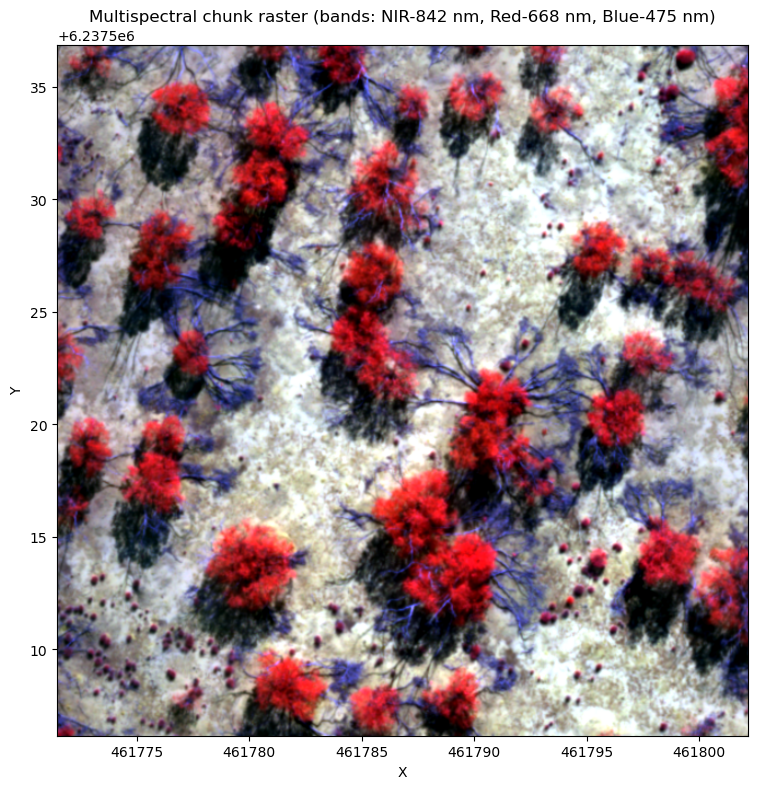

In [34]:
# --- View original raster (bands 5/3/1) ---
import rasterio, numpy as np, matplotlib.pyplot as plt

tile_path = LIDAR_A_TILE
with rasterio.open(tile_path) as src:
    if src.count < 5:
        raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
    b5 = src.read(5).astype(np.float32)
    b3 = src.read(3).astype(np.float32)
    b1 = src.read(1).astype(np.float32)
    def norm_band(b):
        lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
        b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
        b[~np.isfinite(b)] = 0
        return b
    rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(8, 8))
plt.imshow(rgb, extent=extent, origin='upper')
plt.title('Multispectral chunk raster (bands: NIR-842 nm, Red-668 nm, Blue-475 nm)')
plt.xlabel('X'); plt.ylabel('Y')
plt.tight_layout(); plt.show()

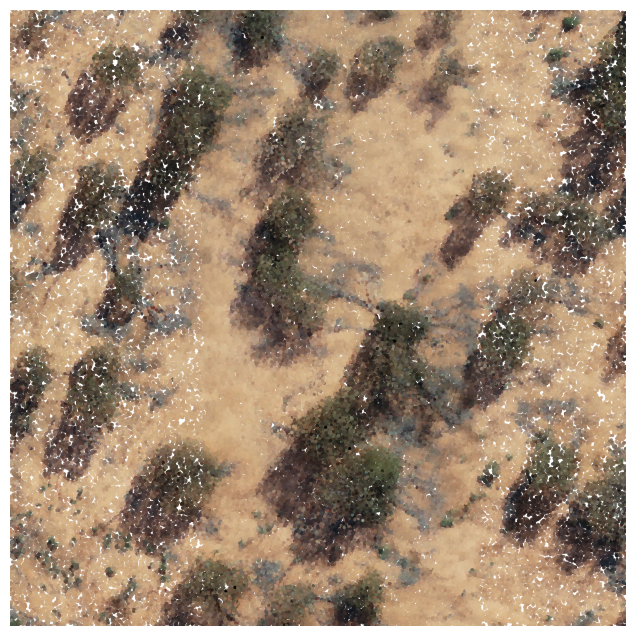

Saved to: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/raster_v2/coreg/tiles_multispectral_109_las_view.jpg


<Figure size 640x480 with 0 Axes>

In [20]:
# --- View LAS only (coloured by RGB if available; else by Z) ---
import laspy, numpy as np, matplotlib.pyplot as plt
import rasterio

# Get extent from raster
with rasterio.open(LIDAR_A_TILE) as src:
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

las_path = LIDAR_OUT_DIR / f"{LIDAR_A_TILE.stem}.las"
if not las_path.exists():
    las_path = sample_out
las = laspy.read(las_path)

x = las.x
y = las.y
use_rgb = hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue')
if use_rgb:
    r = np.asarray(las.red, dtype=np.float32)
    g = np.asarray(las.green, dtype=np.float32)
    b = np.asarray(las.blue, dtype=np.float32)
    colors = np.stack([r, g, b], axis=-1) / 65535.0
else:
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    colors = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

n = len(x); max_pts = 200000
if n > max_pts:
    idx = np.random.choice(n, size=max_pts, replace=False)
    x = x[idx]; y = y[idx]
    colors = colors[idx]

plt.figure(figsize=(8, 8))
# plt.title('LAS points only')
# plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
if use_rgb:
    plt.scatter(x, y, s=2, c=colors, alpha=0.8)
else:
    plt.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.8)
    
plt.xticks([])
plt.yticks([])
plt.box(False)   

out_jpg = LIDAR_OUT_DIR / f"{LIDAR_A_TILE.stem}_las_view.jpg"
plt.savefig(out_jpg, dpi=300, format='jpg', bbox_inches='tight', pad_inches=0)

plt.show()
print(f"Saved to: {out_jpg}") 
    
plt.tight_layout();


Overlay sources:
  Raster: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16/tiles_multispectral_109.tif
  LiDAR point clouds: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las


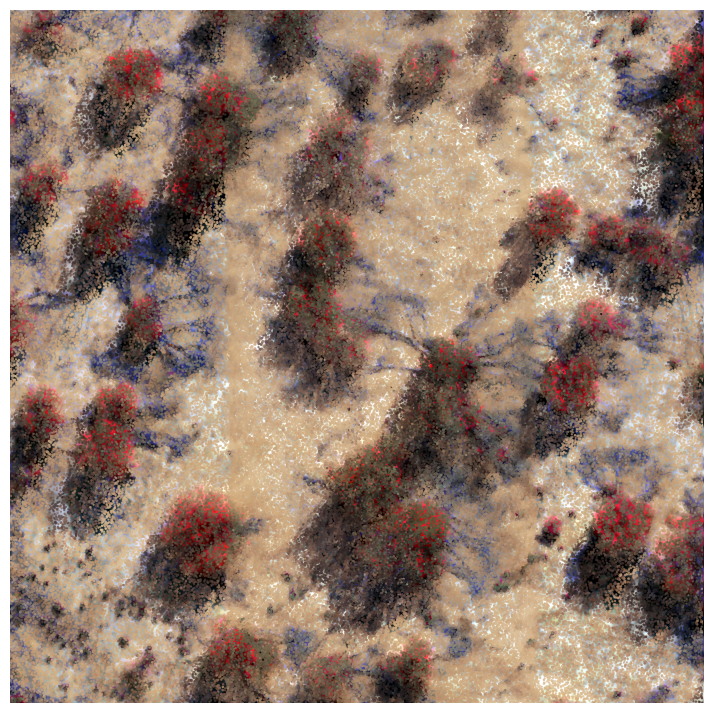

Saved to: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/raster_v2/coreg/tiles_multispectral_109_las_viewMultispec.jpg


<Figure size 640x480 with 0 Axes>

In [21]:
# Add your custom analysis code here
# --- Overlay: Raster 5/3/1 + LAS ---
import matplotlib.pyplot as plt
import rasterio

print(f'Overlay sources:')
print(f'  Raster: {LIDAR_A_TILE}')
print(f'  LiDAR point clouds: {INPUT_LAS}')

# Get extent from raster if not already in scope
try:
    extent
    rgb
except NameError:
    import numpy as np
    with rasterio.open(LIDAR_A_TILE) as src:
        if src.count < 5:
            raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
        b5 = src.read(5).astype(np.float32)
        b3 = src.read(3).astype(np.float32)
        b1 = src.read(1).astype(np.float32)
        def norm_band(b):
            lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
            b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
            b[~np.isfinite(b)] = 0
            return b
        rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(9, 9))
plt.imshow(rgb, extent=extent, origin='upper')
# plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
# plt.title('Overlay: Multispectral raster (NIR-842/Red-668/Blue-475 nm) + LiDAR point clouds')
try:
    cvals = colors
except NameError:
    # compute simple Z colors if colors not in scope
    import numpy as np, laspy
    las = laspy.read(LIDAR_OUT_DIR / f"{LIDAR_A_TILE.stem}.las")
    x = las.x; y = las.y
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    cvals = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

if cvals.ndim == 2:
    plt.scatter(x, y, s=0.5, c=cvals, alpha=0.7)
else:
    plt.scatter(x, y, s=0.5, c=cvals, cmap='viridis', alpha=0.7)
   
plt.xticks([])
plt.yticks([])
plt.box(False)   

out_jpg = LIDAR_OUT_DIR / f"{LIDAR_A_TILE.stem}_las_viewMultispec.jpg"
plt.savefig(out_jpg, dpi=300, format='jpg', bbox_inches='tight', pad_inches=0)

plt.show()
print(f"Saved to: {out_jpg}") 
    
plt.tight_layout();

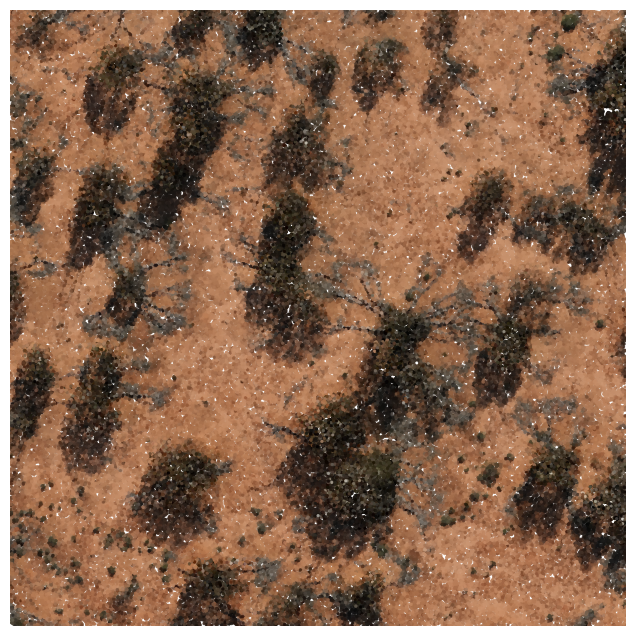

Saved to: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/clipped/raster_v2/tiles_multispectral_109_denseCloud_viewRGB.jpg


<Figure size 640x480 with 0 Axes>

In [15]:
# --- View LAS only (coloured by RGB if available; else by Z) ---
import laspy, numpy as np, matplotlib.pyplot as plt
import rasterio

# Get extent from raster
with rasterio.open(RGB_A_TILE) as src:
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

rgb_path = RGB_OUT_DIR / f"{RGB_A_TILE.stem}.las"
if not rgb_path.exists():
    rgb_path = sample_out
las = laspy.read(rgb_path)

x = las.x
y = las.y
use_rgb = hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue')
if use_rgb:
    r = np.asarray(las.red, dtype=np.float32)
    g = np.asarray(las.green, dtype=np.float32)
    b = np.asarray(las.blue, dtype=np.float32)
    colors = np.stack([r, g, b], axis=-1) / 65535.0
else:
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    colors = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

n = len(x); max_pts = 200000
if n > max_pts:
    idx = np.random.choice(n, size=max_pts, replace=False)
    x = x[idx]; y = y[idx]
    colors = colors[idx]

plt.figure(figsize=(8, 8))
# plt.title('LAS points only')
# plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
if use_rgb:
    plt.scatter(x, y, s=2, c=colors, alpha=0.8)
else:
    plt.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.8)
    
plt.xticks([])
plt.yticks([])
plt.box(False)   

out_jpg = RGB_OUT_DIR / f"{RGB_A_TILE.stem}_denseCloud_viewRGB.jpg"
plt.savefig(out_jpg, dpi=300, format='jpg', bbox_inches='tight', pad_inches=0)

plt.show()
print(f"Saved to: {out_jpg}") 
    
plt.tight_layout();


Overlay sources:
  Raster: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/predictors/tiles_3072/multispec/res_01/stacked/tiles_multispectral_int16/tiles_multispectral_109.tif
  LiDAR point clouds: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las


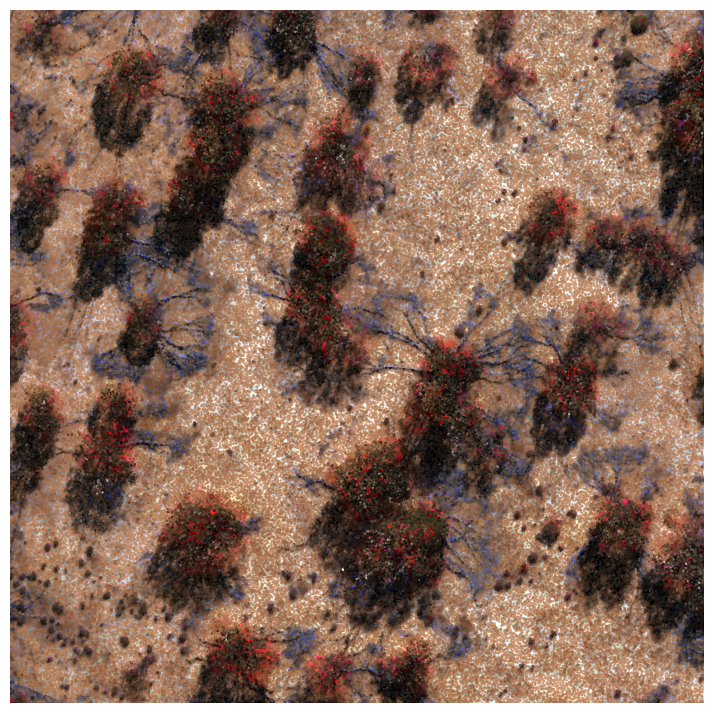

Saved to: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/imagery/clipped/raster_v2/tiles_multispectral_109_denseCloud_viewRGBmultispec.jpg


<Figure size 640x480 with 0 Axes>

In [17]:
# Add your custom analysis code here
# --- Overlay: Raster 5/3/1 + LAS ---
import matplotlib.pyplot as plt
import rasterio

print(f'Overlay sources:')
print(f'  Raster: {LIDAR_A_TILE}')
print(f'  LiDAR point clouds: {INPUT_LAS}')

# Get extent from raster if not already in scope
try:
    extent
    rgb
except NameError:
    import numpy as np
    with rasterio.open(LIDAR_A_TILE) as src:
        if src.count < 5:
            raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
        b5 = src.read(5).astype(np.float32)
        b3 = src.read(3).astype(np.float32)
        b1 = src.read(1).astype(np.float32)
        def norm_band(b):
            lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
            b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
            b[~np.isfinite(b)] = 0
            return b
        rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(9, 9))
plt.imshow(rgb, extent=extent, origin='upper')
# plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
# plt.title('Overlay: Multispectral raster (NIR-842/Red-668/Blue-475 nm) + LiDAR point clouds')
try:
    cvals = colors
except NameError:
    # compute simple Z colors if colors not in scope
    import numpy as np, laspy
    las = laspy.read(LIDAR_OUT_DIR / f"{LIDAR_A_TILE.stem}.las")
    x = las.x; y = las.y
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    cvals = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

if cvals.ndim == 2:
    plt.scatter(x, y, s=0.5, c=cvals, alpha=0.7)
else:
    plt.scatter(x, y, s=0.5, c=cvals, cmap='viridis', alpha=0.7)
   
plt.xticks([])
plt.yticks([])
plt.box(False)   

out_jpg = RGB_OUT_DIR / f"{RGB_A_TILE.stem}_denseCloud_viewRGBmultispec.jpg"
plt.savefig(out_jpg, dpi=300, format='jpg', bbox_inches='tight', pad_inches=0)

plt.show()
print(f"Saved to: {out_jpg}") 
    
plt.tight_layout();

# Additional Analysis

Loading full LiDAR point cloud and all raster tiles...
LiDAR: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
Found 15 raster tiles
Overall extent: X=[461710.02, 462017.22], Y=[6237321.85, 6237721.21]
Loading full LiDAR point cloud...
Total LiDAR points: 278,471,159
Subsampled to: 500,000 points
Plotting LiDAR points...
Overlaying raster tiles (emphasized)...
  Processing raster 10/15...


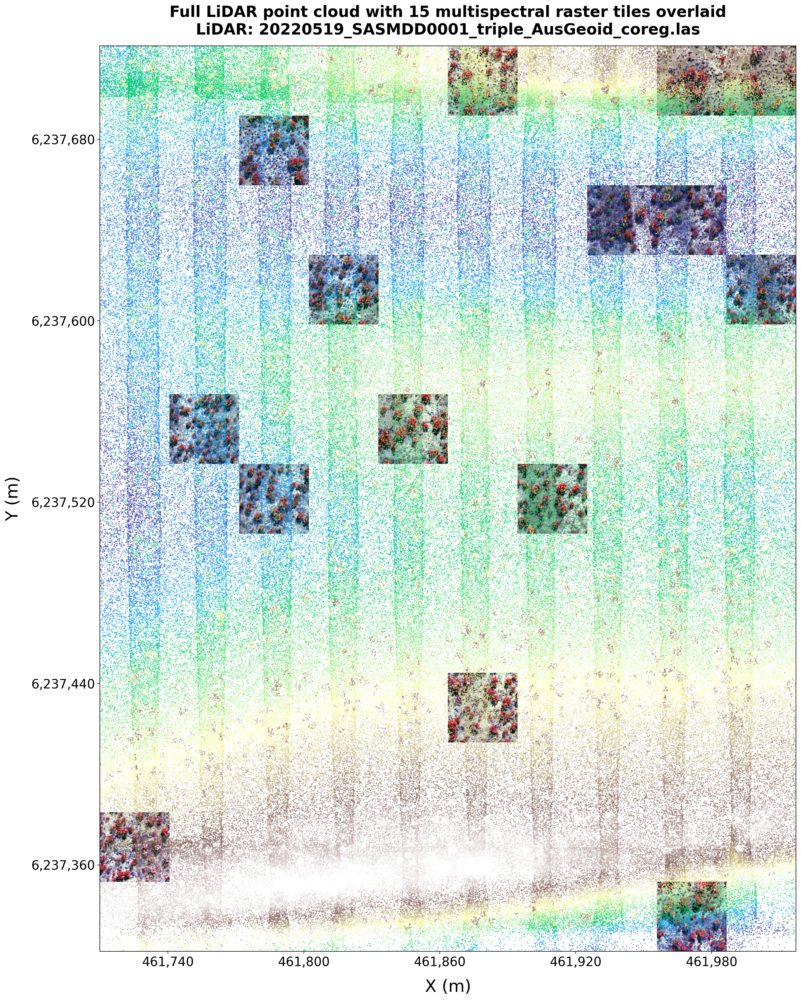

✅ Complete!


In [41]:
# --- Plot full LiDAR with all raster tiles overlaid on top ---
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import rasterio
import laspy
import numpy as np
from pathlib import Path

print('Loading full LiDAR point cloud and all raster tiles...')

# Full LiDAR file
FULL_LIDAR = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las')
print(f'LiDAR: {FULL_LIDAR}')

# Find all raster tiles
raster_files = sorted(LIDAR_AOI_RASTER_DIR.glob(LIDAR_RASTER_PATTERN))
print(f'Found {len(raster_files)} raster tiles')

# Determine the overall extent from all rasters
all_bounds = []
for raster_file in raster_files:
    with rasterio.open(raster_file) as src:
        all_bounds.append(src.bounds)

if all_bounds:
    min_x = min(b.left for b in all_bounds)
    max_x = max(b.right for b in all_bounds)
    min_y = min(b.bottom for b in all_bounds)
    max_y = max(b.top for b in all_bounds)
    overall_extent = (min_x, max_x, min_y, max_y)
    print(f'Overall extent: X=[{min_x:.2f}, {max_x:.2f}], Y=[{min_y:.2f}, {max_y:.2f}]')
else:
    print('No rasters found')
    overall_extent = None

label_fontsize = 24
tick_fontsize = 18
title_fontsize = 22

# Create figure
fig, ax = plt.subplots(figsize=(20, 20), dpi=160)

# Load and plot full LiDAR point cloud (background)
print('Loading full LiDAR point cloud...')
las_full = laspy.read(FULL_LIDAR)
x_full = np.asarray(las_full.x)
y_full = np.asarray(las_full.y)
z_full = np.asarray(las_full.z, dtype=np.float32)

# Subsample LiDAR for performance
max_lidar_points = 500000
n_total = len(x_full)
print(f'Total LiDAR points: {n_total:,}')

if n_total > max_lidar_points:
    idx_full = np.random.choice(n_total, size=max_lidar_points, replace=False)
    x_full = x_full[idx_full]
    y_full = y_full[idx_full]
    z_full = z_full[idx_full]
    print(f'Subsampled to: {max_lidar_points:,} points')

# Color LiDAR by elevation (lighter background)
z_lo, z_hi = np.percentile(z_full, [2, 98])
z_colors = np.clip((z_full - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

print('Plotting LiDAR points...')
ax.scatter(x_full, y_full, s=0.3, c=z_colors, cmap='terrain', alpha=0.6, vmin=0, vmax=1)

# Plot all raster tiles on top (emphasized)
print('Overlaying raster tiles (emphasized)...')
num_rasters_to_plot = len(raster_files)  # Plot all rasters
for i, raster_file in enumerate(raster_files[:num_rasters_to_plot]):
    if (i + 1) % 10 == 0:
        print(f'  Processing raster {i+1}/{num_rasters_to_plot}...')
    
    with rasterio.open(raster_file) as src:
        if src.count >= 5:
            b5 = src.read(5).astype(np.float32)
            b3 = src.read(3).astype(np.float32)
            b1 = src.read(1).astype(np.float32)
            
            def norm_band(b):
                lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
                b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
                b[~np.isfinite(b)] = 0
                return b
            
            rgb_tile = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
            tile_extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
            ax.imshow(rgb_tile, extent=tile_extent, origin='upper', alpha=0.95)

# Set extent and formatting
if overall_extent:
    ax.set_xlim(overall_extent[0], overall_extent[1])
    ax.set_ylim(overall_extent[2], overall_extent[3])
ax.set_aspect('equal')
ax.set_xlabel('X (m)', fontsize=label_fontsize, labelpad=14)
ax.set_ylabel('Y (m)', fontsize=label_fontsize, labelpad=14)
ax.tick_params(axis='both', labelsize=tick_fontsize)
ax.xaxis.set_major_locator(mticker.MaxNLocator(6))
ax.yaxis.set_major_locator(mticker.MaxNLocator(6))
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.set_title(
    f'Full LiDAR point cloud with {len(raster_files)} multispectral raster tiles overlaid\n'
    f'LiDAR: {FULL_LIDAR.name}',
    fontsize=title_fontsize,
    pad=20,
    wrap=True,
    fontweight='semibold',
)
plt.tight_layout()
plt.show()

print('✅ Complete!')

Loading full LiDAR point cloud and all raster tiles...
LiDAR: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
Found 15 raster tiles
Overall extent: X=[461710.02, 462017.22], Y=[6237321.85, 6237721.21]
Loading full LiDAR point cloud...


Total LiDAR points: 278,471,159
Subsampled to: 500,000 points
Plotting LiDAR points...
Overlaying raster tiles (emphasized)...
  Processing raster 10/15...
Saved figure to: full_lidar_raster_overlay.jpg


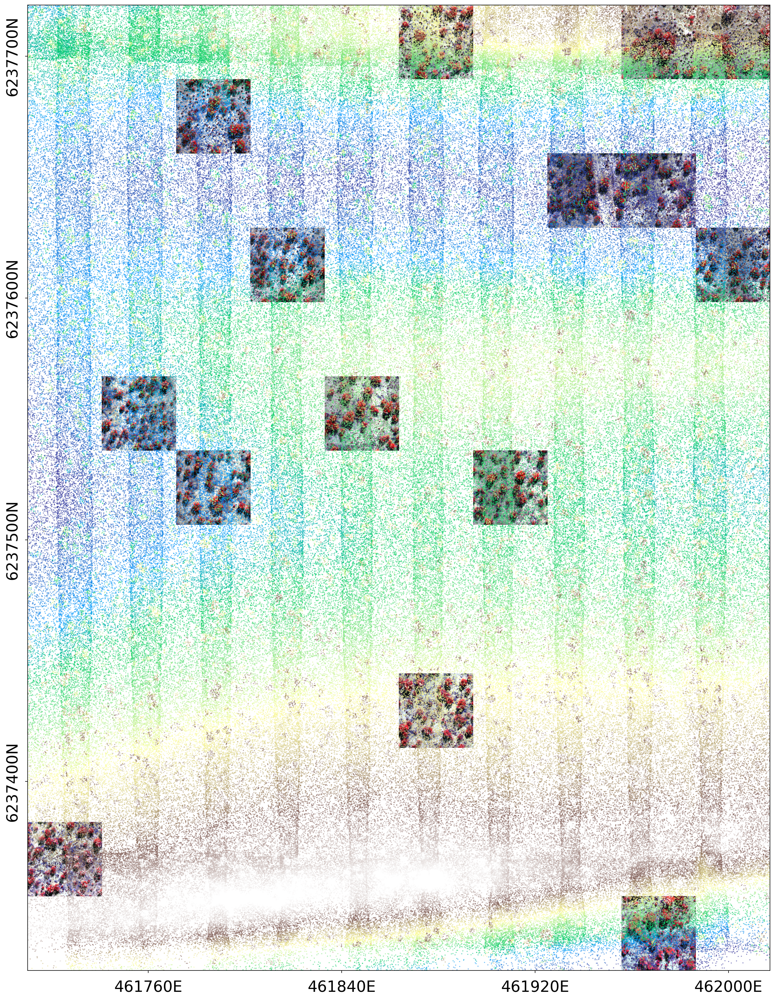

✅ Complete!


In [ ]:
#version 2
# --- Plot full LiDAR with all raster tiles overlaid on top ---
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import rasterio
import laspy
import numpy as np
from pathlib import Path

print('Loading full LiDAR point cloud and all raster tiles...')

# Full LiDAR file
FULL_LIDAR = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las')
print(f'LiDAR: {FULL_LIDAR}')

# Find all raster tiles
raster_files = sorted(LIDAR_AOI_RASTER_DIR.glob(LIDAR_RASTER_PATTERN))
print(f'Found {len(raster_files)} raster tiles')

# Determine the overall extent from all rasters
all_bounds = []
for raster_file in raster_files:
    with rasterio.open(raster_file) as src:
        all_bounds.append(src.bounds)

if all_bounds:
    min_x = min(b.left for b in all_bounds)
    max_x = max(b.right for b in all_bounds)
    min_y = min(b.bottom for b in all_bounds)
    max_y = max(b.top for b in all_bounds)
    overall_extent = (min_x, max_x, min_y, max_y)
    print(f'Overall extent: X=[{min_x:.2f}, {max_x:.2f}], Y=[{min_y:.2f}, {max_y:.2f}]')
else:
    print('No rasters found')
    overall_extent = None

tick_fontsize = 22
title_fontsize = 28

fig, ax = plt.subplots(figsize=(20, 20), dpi=160)

# Load LiDAR
print('Loading full LiDAR point cloud...')
las_full = laspy.read(FULL_LIDAR)
x_full = np.asarray(las_full.x)
y_full = np.asarray(las_full.y)
z_full = np.asarray(las_full.z, dtype=np.float32)

# Subsample for performance
max_lidar_points = 500000
n_total = len(x_full)
print(f'Total LiDAR points: {n_total:,}')

if n_total > max_lidar_points:
    idx_full = np.random.choice(n_total, size=max_lidar_points, replace=False)
    x_full = x_full[idx_full]
    y_full = y_full[idx_full]
    z_full = z_full[idx_full]
    print(f'Subsampled to: {max_lidar_points:,} points')

# Color LiDAR by elevation
z_lo, z_hi = np.percentile(z_full, [2, 98])
z_colors = np.clip((z_full - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

print('Plotting LiDAR points...')
ax.scatter(
    x_full, y_full,
    s=0.3,
    c=z_colors,
    cmap='terrain',
    alpha=0.6,
    vmin=0,
    vmax=1
)

# Overlay raster tiles
print('Overlaying raster tiles (emphasized)...')
num_rasters_to_plot = len(raster_files)

for i, raster_file in enumerate(raster_files[:num_rasters_to_plot]):
    if (i + 1) % 10 == 0:
        print(f'  Processing raster {i+1}/{num_rasters_to_plot}...')

    with rasterio.open(raster_file) as src:
        if src.count >= 5:
            b5 = src.read(5).astype(np.float32)
            b3 = src.read(3).astype(np.float32)
            b1 = src.read(1).astype(np.float32)

            def norm_band(b):
                finite = np.isfinite(b)
                if not np.any(finite):
                    return np.zeros_like(b, dtype=np.float32)
                lo, hi = np.percentile(b[finite], [2, 98])
                b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
                b[~finite] = 0
                return b

            rgb_tile = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
            tile_extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
            ax.imshow(rgb_tile, extent=tile_extent, origin='upper', alpha=0.95)

# Set extent and formatting
if overall_extent:
    ax.set_xlim(overall_extent[0], overall_extent[1])
    ax.set_ylim(overall_extent[2], overall_extent[3])

ax.set_aspect('equal')

# Remove axis labels
ax.set_xlabel('')
ax.set_ylabel('')

# Tick size
ax.tick_params(axis='both', labelsize=tick_fontsize)

# Tick locations
ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
ax.yaxis.set_major_locator(mticker.MaxNLocator(4))

# Coordinate format with E / N suffix
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f'{x:.0f}E'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, pos: f'{y:.0f}N'))

# X labels horizontal
plt.setp(ax.get_xticklabels(), rotation=0, ha='center')

# Y labels vertical like the picture
plt.setp(ax.get_yticklabels(), rotation=90, va='center', ha='center')

# Padding
ax.tick_params(axis='y', pad=18)
ax.tick_params(axis='x', pad=10)

# ax.set_title(
#     f'Full LiDAR point cloud with {len(raster_files)} multispectral raster tiles overlaid\n'
#     f'LiDAR: {FULL_LIDAR.name}',
#     fontsize=title_fontsize,
#     pad=24,
#     wrap=True,
#     fontweight='semibold'
# )

plt.tight_layout()

# Save figure as JPEG at 300 DPI
output_path = "full_lidar_raster_overlay.jpg"
fig.savefig(output_path, format='jpg', dpi=300, bbox_inches='tight')
print(f"Saved figure to: {output_path}")

plt.show()

print('✅ Complete!')

Loading full LiDAR point cloud and all raster tiles...
LiDAR: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
Found 15 raster tiles
Overall extent: X=[461710.02, 462017.22], Y=[6237321.85, 6237721.21]
Loading full LiDAR point cloud...
Total LiDAR points: 278,471,159
Subsampled to: 500,000 points
Plotting LiDAR points...
Overlaying raster tiles...
  Processing raster 10/15...
Scale bar based on overall extent: x_range=307 m, total_length=20 m (4 x 5 m), label_every=2
Saved figure to: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/full_lidar_raster_overlay.jpg


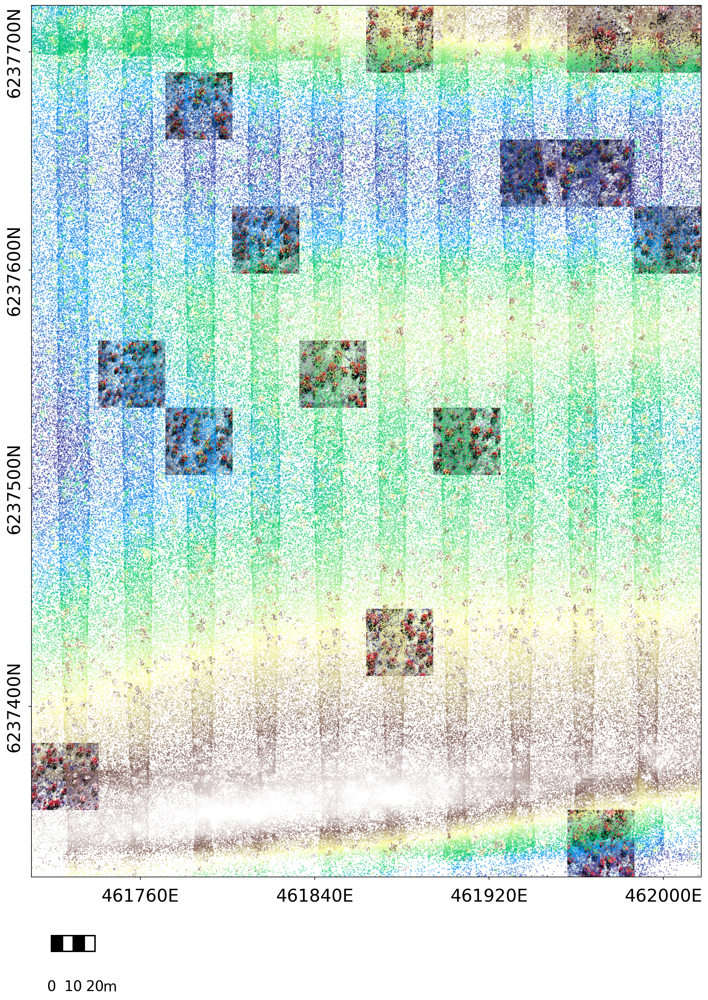

✅ Complete!


In [6]:
#version 3
# --- Plot full LiDAR with all raster tiles overlaid on top ---
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as patches
import matplotlib.transforms as transforms
import rasterio
import laspy
import numpy as np
from pathlib import Path

print('Loading full LiDAR point cloud and all raster tiles...')

# Full LiDAR file
FULL_LIDAR = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las')
print(f'LiDAR: {FULL_LIDAR}')

# Output JPEG path
OUTPUT_JPG = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/full_lidar_raster_overlay.jpg')

# Find all raster tiles
raster_files = sorted(LIDAR_AOI_RASTER_DIR.glob(LIDAR_RASTER_PATTERN))
print(f'Found {len(raster_files)} raster tiles')

# Determine overall extent from all rasters
all_bounds = []
for raster_file in raster_files:
    with rasterio.open(raster_file) as src:
        all_bounds.append(src.bounds)

if all_bounds:
    min_x = min(b.left for b in all_bounds)
    max_x = max(b.right for b in all_bounds)
    min_y = min(b.bottom for b in all_bounds)
    max_y = max(b.top for b in all_bounds)
    overall_extent = (min_x, max_x, min_y, max_y)
    print(f'Overall extent: X=[{min_x:.2f}, {max_x:.2f}], Y=[{min_y:.2f}, {max_y:.2f}]')
else:
    print('No rasters found')
    overall_extent = None

# Font sizes
tick_fontsize = 22
scale_fontsize = 18
north_fontsize = 24

# Create figure
fig, ax = plt.subplots(figsize=(20, 20), dpi=160)


def norm_band(b):
    """Normalize raster band to 0-1 using a 2nd-98th percentile stretch."""
    finite = np.isfinite(b)
    if not np.any(finite):
        return np.zeros_like(b, dtype=np.float32)
    lo, hi = np.percentile(b[finite], [2, 98])
    out = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
    out[~finite] = 0
    return out


def nice_number(x):
    """
    Round down to a 'nice' cartographic number:
    1, 2, or 5 times a power of 10.
    """
    if x <= 0:
        return 1

    exponent = np.floor(np.log10(x))
    fraction = x / (10 ** exponent)

    if fraction >= 5:
        nice_fraction = 5
    elif fraction >= 2:
        nice_fraction = 2
    else:
        nice_fraction = 1

    return nice_fraction * (10 ** exponent)


def add_scale_bar_below(
    ax,
    bar_frac=0.18,           # total scale bar length = 12% of map width
    segments=4,
    x_left_frac=0.03,        # left position below map
    y_axes=-0.16,           # bar vertical position in axes fraction
    bar_height_axes=0.03,   # bar height in axes fraction
    text_y_axes=-0.195,      # text position below bar
    fontsize=18,
    linewidth=1.8,
    min_label_sep_px=44
):
    """
    Add a segmented black/white scale bar below the map.
    The length is based on the CURRENT x extent, which here is set from the overall extent.
    """
    xlim = ax.get_xlim()
    x_min, x_max = min(xlim), max(xlim)
    x_range = x_max - x_min

    # Target scale bar length from overall extent
    target_total_length = x_range * bar_frac
    target_segment_length = target_total_length / segments

    # Round segment length to a nice number
    segment_length = nice_number(target_segment_length)
    total_length = segment_length * segments

    # Left position in data coordinates
    x0 = x_min + x_left_frac * x_range

    # Mixed transform: x in data units, y in axes fraction
    trans = transforms.blended_transform_factory(ax.transData, ax.transAxes)

    # Draw the bar
    for i in range(segments):
        xi = x0 + i * segment_length
        facecolor = 'black' if i % 2 == 0 else 'white'
        rect = patches.Rectangle(
            (xi, y_axes),
            segment_length,
            bar_height_axes,
            transform=trans,
            facecolor=facecolor,
            edgecolor='black',
            linewidth=linewidth,
            clip_on=False,
            zorder=20
        )
        ax.add_patch(rect)

    # Outer border
    border = patches.Rectangle(
        (x0, y_axes),
        total_length,
        bar_height_axes,
        transform=trans,
        facecolor='none',
        edgecolor='black',
        linewidth=linewidth,
        clip_on=False,
        zorder=21
    )
    ax.add_patch(border)

    # Estimate segment width in pixels to avoid text overlap
    p0 = ax.transData.transform((x0, 0))
    p1 = ax.transData.transform((x0 + segment_length, 0))
    segment_px = abs(p1[0] - p0[0])

    label_every = 1
    if segment_px < min_label_sep_px:
        label_every = 2
    if segment_px < min_label_sep_px / 2:
        label_every = segments

    # Label positions
    for i in range(segments + 1):
        if i not in (0, segments) and (i % label_every != 0):
            continue

        xi = x0 + i * segment_length
        ax.text(
            xi,
            text_y_axes,
            f'{int(i * segment_length)}',
            transform=trans,
            ha='center',
            va='top',
            fontsize=fontsize,
            color='black',
            clip_on=False,
            zorder=22
        )

    # Unit label placed with extra spacing so it does not collide
    ax.text(
        x0 + total_length + 0.012 * x_range,
        text_y_axes,
        'm',
        transform=trans,
        ha='left',
        va='top',
        fontsize=fontsize,
        color='black',
        clip_on=False,
        zorder=22
    )

    print(
        f'Scale bar based on overall extent: '
        f'x_range={x_range:.0f} m, total_length={total_length:.0f} m '
        f'({segments} x {segment_length:.0f} m), label_every={label_every}'
    )


def add_north_arrow(
    ax,
    x=0.11,
    y=0.03,
    arrow_length=0.08,
    fontsize=north_fontsize
):
    ax.annotate(
        '',
        xy=(x, y + arrow_length),
        xytext=(x, y),
        xycoords='axes fraction',
        arrowprops=dict(
            facecolor='black',
            edgecolor='black',
            width=4,
            headwidth=16,
            headlength=16
        ),
        annotation_clip=False
    )

    ax.text(
        x,
        y + arrow_length + 0.02,
        'N',
        transform=ax.transAxes,
        ha='center',
        va='bottom',
        fontsize=fontsize,
        fontweight='bold',
        color='black',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.2),
        clip_on=False
    )


# Load LiDAR
print('Loading full LiDAR point cloud...')
las_full = laspy.read(FULL_LIDAR)
x_full = np.asarray(las_full.x)
y_full = np.asarray(las_full.y)
z_full = np.asarray(las_full.z, dtype=np.float32)

# Subsample LiDAR for performance
max_lidar_points = 500000
n_total = len(x_full)
print(f'Total LiDAR points: {n_total:,}')

if n_total > max_lidar_points:
    idx_full = np.random.choice(n_total, size=max_lidar_points, replace=False)
    x_full = x_full[idx_full]
    y_full = y_full[idx_full]
    z_full = z_full[idx_full]
    print(f'Subsampled to: {max_lidar_points:,} points')

# Color LiDAR by elevation
z_lo, z_hi = np.percentile(z_full, [2, 98])
z_colors = np.clip((z_full - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

print('Plotting LiDAR points...')
ax.scatter(
    x_full,
    y_full,
    s=0.3,
    c=z_colors,
    cmap='terrain',
    alpha=0.6,
    vmin=0,
    vmax=1
)

# Overlay raster tiles
print('Overlaying raster tiles...')
num_rasters_to_plot = len(raster_files)

for i, raster_file in enumerate(raster_files[:num_rasters_to_plot]):
    if (i + 1) % 10 == 0:
        print(f'  Processing raster {i + 1}/{num_rasters_to_plot}...')

    with rasterio.open(raster_file) as src:
        if src.count >= 5:
            b5 = src.read(5).astype(np.float32)
            b3 = src.read(3).astype(np.float32)
            b1 = src.read(1).astype(np.float32)

            rgb_tile = np.stack(
                [norm_band(b5), norm_band(b3), norm_band(b1)],
                axis=-1
            )

            tile_extent = (
                src.bounds.left,
                src.bounds.right,
                src.bounds.bottom,
                src.bounds.top
            )

            ax.imshow(
                rgb_tile,
                extent=tile_extent,
                origin='upper',
                alpha=0.95
            )

# Set extent from overall extent
if overall_extent:
    ax.set_xlim(overall_extent[0], overall_extent[1])
    ax.set_ylim(overall_extent[2], overall_extent[3])

ax.set_aspect('equal')

# Remove axis labels
ax.set_xlabel('')
ax.set_ylabel('')

# Tick styling
ax.tick_params(axis='both', labelsize=tick_fontsize)
ax.tick_params(axis='y', pad=18)
ax.tick_params(axis='x', pad=10)

# Tick locations
ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
ax.yaxis.set_major_locator(mticker.MaxNLocator(4))

# Tick formatting
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f'{x:.0f}E'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, pos: f'{y:.0f}N'))

# Tick label orientation
plt.setp(ax.get_xticklabels(), rotation=0, ha='center')
plt.setp(ax.get_yticklabels(), rotation=90, va='center', ha='center')

# Add north arrow
# add_north_arrow(
#     ax,
#     x=0.94,
#     y=0.92,
#     arrow_length=0.08,
#     fontsize=north_fontsize
# )

# Add scale bar below map, based on overall extent
add_scale_bar_below(
    ax,
    bar_frac=0.12,
    segments=4,
    x_left_frac=0.03,
    y_axes=-0.085,
    bar_height_axes=0.018,
    text_y_axes=-0.118,
    fontsize=scale_fontsize
)

# Leave extra space below for scale bar
plt.tight_layout(rect=(0, 0.12, 1, 1))

# Save figure as JPEG at 300 DPI
fig.savefig(
    OUTPUT_JPG,
    format='jpg',
    dpi=300,
    bbox_inches='tight'
)
print(f'Saved figure to: {OUTPUT_JPG}')

plt.show()
#ve
print('✅ Complete!')